# Huella Compatible: prototipo de sistema recomendador para adopción responsable

**Taller de Sistemas Recomendadores · Parte 2.3 · Grupo 2: Carlos Sánchez y Cristian Molina**

Este cuaderno implementa un recomendador **basado principalmente en contenido** que empareja adoptantes con perros y gatos en adopción. El sistema es un híbrido en cascada:

1. **Filtro basado en conocimiento:** reglas duras que salen del cuestionario (vivienda, niños, otras mascotas, presupuesto).
2. **Filtrado basado en contenido:** similitud entre el "animal ideal" del adoptante y cada ficha (similitud de Gower sobre atributos + coseno TF-IDF sobre la descripción).
3. **Re-ranking de equidad y diversidad** (Parte 3): se compara la versión base con la mitigada.

**Cómo ejecutarlo:** abrir este cuaderno desde la carpeta `notebooks/` y ejecutar todas las celdas (*Run All*). Requiere `pandas`, `numpy`, `scikit-learn` y `matplotlib` (ver `requirements.txt`). Tarda menos de un minuto.

| Sección | Contenido |
| --- | --- |
| 1 | Fuente y carga del dataset |
| 2 | Exploración y sesgos preexistentes en los datos |
| 3 | Ingeniería de atributos (temperamento a partir del texto) |
| 4 | Representación de ítems y **criterio de similaridad** |
| 5 | Cuestionario → perfil del adoptante (arranque en frío del usuario) |
| 6 | Motor de recomendación y explicaciones |
| 7 | Demostración con tres perfiles de usuario |
| 8 | Ajuste del perfil en la sesión (Rocchio) |
| 9 | Arranque en frío del ítem: un animal recién publicado |
| 10 | Evaluación offline |
| 11 | Medición de sesgos y efecto de la mitigación |
| 12 | Conclusiones |

In [1]:
import re
import warnings
from dataclasses import dataclass, replace
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.metrics.pairwise import linear_kernel
from sklearn.preprocessing import normalize
from scipy import sparse

warnings.filterwarnings("ignore", category=FutureWarning)
warnings.filterwarnings("ignore", message="This pattern is interpreted as a regular expression")
pd.set_option("display.max_colwidth", None)
pd.set_option("display.width", 160)

DATA = Path("../data")
FIG = Path("../figuras")
FIG.mkdir(exist_ok=True)
SEMILLA = 42  # todas las simulaciones son reproducibles

## 1. Fuente y carga del dataset

**Dataset:** *PetFinder.my Adoption Prediction* (Kaggle, 2019). Son fichas reales de perros y gatos publicadas en PetFinder.my, el portal de adopción más grande de Malasia.

- **Origen de los archivos:** el conjunto de entrenamiento original de Kaggle (14.993 fichas), obtenido de la copia pública que usa la librería AutoGluon (`train.csv` + `dev.csv` = el *train* de Kaggle), y las tablas de nombres de razas, colores y estados de la competencia.
- **Archivos en `data/`:** `petfinder_train.csv`, `breed_labels.csv`, `color_labels.csv`, `state_labels.csv`.
- **Licencia:** datos de la competencia de Kaggle, uso académico.

| Columna | Significado |
| --- | --- |
| `Type` | 1 = perro, 2 = gato |
| `Age` | Edad en meses al publicar |
| `Breed1`, `Breed2` | Raza principal y secundaria |
| `Gender` | 1 = macho, 2 = hembra, 3 = grupo mixto |
| `Color1..3` | Colores del pelaje |
| `MaturitySize` | Tamaño adulto: 1 pequeño, 2 mediano, 3 grande, 4 extra grande |
| `FurLength` | Pelo: 1 corto, 2 medio, 3 largo |
| `Vaccinated`, `Dewormed`, `Sterilized` | 1 sí, 2 no, 3 no se sabe |
| `Health` | 1 sano, 2 lesión leve, 3 lesión grave |
| `Quantity` | Número de animales en la ficha |
| `Fee` | Costo de adopción (MYR, 0 = gratis) |
| `PhotoAmt`, `VideoAmt` | Número de fotos y videos |
| `Description` | Texto libre del rescatista |
| `AdoptionSpeed` | 0 = el mismo día, 1 = 1–7 días, 2 = 8–30 días, 3 = 31–90 días, 4 = no adoptado a los 100 días |

`AdoptionSpeed` **no se usa para recomendar**. Solo sirve para medir los sesgos preexistentes (sección 2) y como línea base de popularidad (sección 10).

In [2]:
crudo = pd.read_csv(DATA / "petfinder_train.csv")
razas = pd.read_csv(DATA / "breed_labels.csv").set_index("BreedID")["BreedName"]
colores = pd.read_csv(DATA / "color_labels.csv").set_index("ColorID")["ColorName"]
estados = pd.read_csv(DATA / "state_labels.csv").set_index("StateID")["StateName"]

print(f"Fichas en el dataset: {len(crudo):,}")
print(f"Perros: {(crudo.Type == 1).sum():,} · Gatos: {(crudo.Type == 2).sum():,}")
crudo.head(3)

Fichas en el dataset: 14,993
Perros: 8,132 · Gatos: 6,861


,Type,Name,Age,Breed1,Breed2,Gender,Color1,Color2,Color3,MaturitySize,...,Health,Quantity,Fee,State,RescuerID,VideoAmt,Description,PetID,PhotoAmt,AdoptionSpeed
0,2,Ollie,6,265,0,1,4,7,0,2,...,1,1,100,41326,a0f2046e9c9ee30051e07a8e2f5fb392,0,Ollie was rescued from the construction site behind my house. He is quite the manja type and loves to play. He makes a good companion and playmate for young children. He is quite the handsome chap with a distinct mark on his face like a beauty mark.,0008c5398,6.0,3
1,1,Cutie Pie,2,307,0,2,1,2,7,2,...,1,1,0,41327,fd970cc91d06d82eebf046340137b272,0,"went to teluk kumba kuanthai restaurant saw this female puppies alone by the beach.. Adopters must vaccinate, spay and keep puppy indoors/fenced Call/WhatsApp: Address: teluk kumba",000a290e4,2.0,2
2,1,Minnie,2,307,0,2,1,0,0,2,...,1,1,0,41401,d71bf8652469d7c37ed212d0c97c3fd3,0,"This puppy rescued from DBKL pound last wednesday, and been sent to vet for check out. Pls give this lovely puppy a loving home if you can.",000fb9572,6.0,3


**Decisión de limpieza:** se conservan solo las fichas de **un animal** (`Quantity == 1`). Las fichas de camadas mezclan varios animales con edades, sexos y temperamentos distintos, así que no representan un ítem único recomendable.

In [3]:
df = crudo[crudo["Quantity"] == 1].copy().reset_index(drop=True)
df["Description"] = df["Description"].fillna("")

# Decodificación a etiquetas legibles (en español para la presentación)
df["especie"] = df["Type"].map({1: "Perro", 2: "Gato"})
df["raza"] = df["Breed1"].map(razas).fillna("Desconocida")
df["color"] = df["Color1"].map(colores)
df["region"] = df["State"].map(estados)
df["sexo"] = df["Gender"].map({1: "Macho", 2: "Hembra"})
df["tamano"] = df["MaturitySize"].map({1: "Pequeño", 2: "Mediano", 3: "Grande", 4: "Extra grande"})
df["pelo"] = df["FurLength"].map({1: "Corto", 2: "Medio", 3: "Largo"})
df["salud"] = df["Health"].map({1: "Sano", 2: "Lesión leve", 3: "Lesión grave"})
df["etapa"] = pd.cut(df["Age"], [-1, 11, 35, 95, 1000],
                     labels=["Cachorro", "Joven", "Adulto", "Senior"]).astype(str)
df["n_palabras"] = df["Description"].str.split().str.len()

print(f"Fichas de un solo animal: {len(df):,} ({len(df) / len(crudo):.0%} del total)")
df[["Name", "especie", "raza", "etapa", "tamano", "pelo", "salud", "Fee", "n_palabras"]].head()

Fichas de un solo animal: 11,565 (77% del total)


,Name,especie,raza,etapa,tamano,pelo,salud,Fee,n_palabras
0,Ollie,Gato,Domestic Medium Hair,Cachorro,Mediano,Medio,Sano,100,47
1,Cutie Pie,Perro,Mixed Breed,Cachorro,Mediano,Medio,Sano,0,26
2,Minnie,Perro,Mixed Breed,Cachorro,Mediano,Corto,Sano,0,27
3,Spot,Gato,Abyssinian,Cachorro,Mediano,Corto,Sano,0,8
4,Pup,Perro,Mixed Breed,Cachorro,Mediano,Corto,Sano,0,75


## 2. Exploración: sesgos preexistentes en los datos

Antes de recomendar, medimos qué animales **ya tienen desventaja** en el mundo real. Usamos la tasa de animales **no adoptados a los 100 días** (`AdoptionSpeed == 4`) por grupo.

Los grupos se eligieron por la literatura y por el contexto colombiano:

- **Edad:** los animales adultos y senior pasan más tiempo en refugios (Hoffman y Svoboda, 2016).
- **Razas de la Ley 746 de 2002:** en Colombia, la ley y el Código de Policía (Ley 1801 de 2016) clasifican ciertas razas como "potencialmente peligrosas", lo que les impone requisitos extra (póliza, bozal) y estigma.
- **Pelaje negro:** el supuesto "síndrome del perro negro", que estudios recientes no confirman.
- **Presentación de la ficha:** sin fotos o con descripción corta (menos de 20 palabras).

In [4]:
RAZAS_LEY_746 = {
    "Pit Bull Terrier", "American Staffordshire Terrier", "Staffordshire Bull Terrier",
    "Rottweiler", "Doberman Pinscher", "Bull Terrier", "Dogo Argentino", "Fila Brasileiro",
    "Japanese Tosa", "Bullmastiff", "Neapolitan Mastiff", "Dogue de Bordeaux",
}
print("Razas de la lista presentes en el dataset:",
      sorted(RAZAS_LEY_746 & set(df["raza"])))

df["grupo_adulto"] = df["Age"] >= 36                       # 3 años o más
df["grupo_ley746"] = (df["Type"] == 1) & df["raza"].isin(RAZAS_LEY_746)
df["grupo_negro"] = df["Color1"] == 1
df["grupo_sin_foto"] = df["PhotoAmt"] == 0
df["grupo_desc_corta"] = df["n_palabras"] < 20
df["no_adoptado_100d"] = df["AdoptionSpeed"] == 4

GRUPOS = {
    "grupo_adulto": "Adulto o senior (≥ 3 años)",
    "grupo_ley746": "Raza Ley 746 (perros)",
    "grupo_negro": "Pelaje negro",
    "grupo_sin_foto": "Sin fotos",
    "grupo_desc_corta": "Descripción < 20 palabras",
}

filas = []
for col, nombre in GRUPOS.items():
    dentro, fuera = df[df[col]], df[~df[col]]
    filas.append({
        "grupo": nombre,
        "n": len(dentro),
        "% del catálogo": 100 * df[col].mean(),
        "% no adoptado (grupo)": 100 * dentro["no_adoptado_100d"].mean(),
        "% no adoptado (resto)": 100 * fuera["no_adoptado_100d"].mean(),
    })
sesgo_pre = pd.DataFrame(filas)
sesgo_pre["razón de riesgo"] = sesgo_pre["% no adoptado (grupo)"] / sesgo_pre["% no adoptado (resto)"]
print(f"Tasa global de no adopción a 100 días: {df['no_adoptado_100d'].mean():.1%}")
sesgo_pre.round(2)

Razas de la lista presentes en el dataset: ['American Staffordshire Terrier', 'Bull Terrier', 'Bullmastiff', 'Doberman Pinscher', 'Pit Bull Terrier', 'Rottweiler', 'Staffordshire Bull Terrier']
Tasa global de no adopción a 100 días: 26.6%


,grupo,n,% del catálogo,% no adoptado (grupo),% no adoptado (resto),razón de riesgo
0,Adulto o senior (≥ 3 años),1240,10.72,35.89,25.52,1.41
1,Raza Ley 746 (perros),179,1.55,18.44,26.76,0.69
2,Pelaje negro,5261,45.49,26.44,26.79,0.99
3,Sin fotos,235,2.03,58.30,25.98,2.24
4,Descripción < 20 palabras,2764,23.90,29.92,25.60,1.17


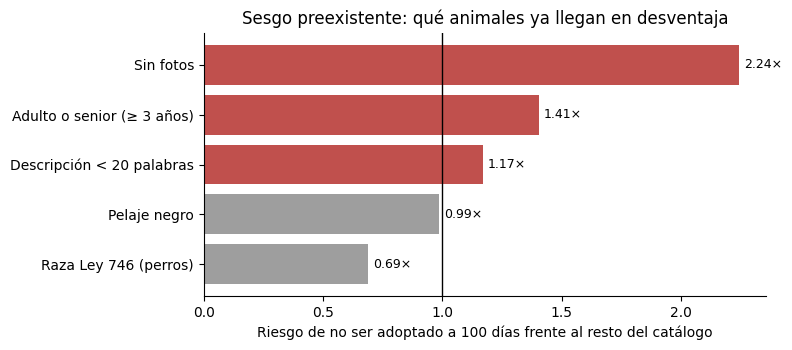

In [5]:
fig, ax = plt.subplots(figsize=(8, 3.6))
orden = sesgo_pre.sort_values("razón de riesgo")
colores_barra = ["#c0504d" if r > 1.15 else "#9e9e9e" for r in orden["razón de riesgo"]]
ax.barh(orden["grupo"], orden["razón de riesgo"], color=colores_barra)
ax.axvline(1, color="black", lw=1)
for y, r in enumerate(orden["razón de riesgo"]):
    ax.text(r + 0.02, y, f"{r:.2f}×", va="center", fontsize=9)
ax.set_xlabel("Riesgo de no ser adoptado a 100 días frente al resto del catálogo")
ax.set_title("Sesgo preexistente: qué animales ya llegan en desventaja")
ax.spines[["top", "right"]].set_visible(False)
plt.tight_layout()
plt.savefig(FIG / "sesgo_preexistente.png", dpi=160)
plt.show()

**Lectura:**

- **Fichas sin fotos (2,24×), animales adultos o senior (1,41×) y descripciones cortas (1,17×)** tienen claramente más riesgo de quedarse sin hogar.
- **Pelaje negro (0,99×):** no hay diferencia. Coincide con Hoffman y Svoboda (2016), que tampoco encontraron el "síndrome del perro negro".
- **Razas de la Ley 746 (0,69×):** en estos datos de Malasia *no* aparecen en desventaja (solo 179 fichas). No podemos trasladar esa conclusión a Bogotá: es un ejemplo de **sesgo de selección del dataset**, que se discute en la Parte 3.

Si el recomendador aprendiera de `AdoptionSpeed` (por ejemplo, ordenando por popularidad), reproduciría estas desventajas. Por eso el motor **no usa** esa variable, y la sección 11 mide si nuestro ranking amplifica o no las brechas.

## 3. Ingeniería de atributos: temperamento a partir del texto

Los atributos estructurados no dicen nada del **temperamento**, que es lo que más explica las devoluciones (comportamiento e incompatibilidad con otras mascotas). Esa información está en la descripción libre.

Extraemos rasgos con **expresiones regulares** sobre el texto (en inglés, con algunos términos en malayo como *manja* = cariñoso). Es un método simple, transparente y auditable; en producción se reemplazaría por un clasificador entrenado.

Cada rasgo se codifica en [0, 1] con un valor **neutro de 0,5 cuando la ficha no dice nada**. La falta de información no se trata como algo positivo ni negativo.

In [6]:
PATRONES = {
    "energia_alta": r"\b(active|playful|energetic|hyper|lively|naughty|aktif|loves to (run|play))\b",
    "energia_baja": r"\b(calm|quiet|gentle|lazy|laid[- ]back|relaxed|docile|mellow|tenang)\b",
    "ninos_si": r"\b(good|great|ok|okay|friendly|gentle|fine|loves|likes) (with )?(kids|children|child)\b|\b(kid|child)[- ]friendly\b",
    "ninos_no": r"\bnot (good|suitable|ok|okay|friendly) (with|for) (small )?(kids|children)\b",
    "perros_si": r"\b(good|gets along|get along|friendly|fine|ok|okay|lives|living|stays) with (other )?dogs\b",
    "perros_no": r"\bnot (good|friendly|ok|okay) with (other )?dogs\b|\b(only dog|no other dogs)\b",
    "gatos_si": r"\b(good|gets along|get along|friendly|fine|ok|okay|lives|living|stays) with (other )?cats\b",
    "gatos_no": r"\bnot (good|friendly|ok|okay) with (other )?cats\b|\b(only cat|no other cats|chases cats)\b",
    "entrenado": r"\b(toilet|litter|potty|house)[- ]?(trained|train)\b|\buses? (the )?litter\b",
    "timido": r"\b(shy|timid|scared|fearful|nervous|takut)\b",
    "carinoso": r"\b(manja|affectionate|loving|cuddly|sweet|friendly)\b",
}
texto = df["Description"].str.lower()
for rasgo, patron in PATRONES.items():
    df[rasgo] = texto.str.contains(patron, regex=True)


def tri(si, no):
    """1 = la ficha lo afirma, 0 = la ficha lo niega, 0.5 = no hay información."""
    return np.where(si, 1.0, np.where(no, 0.0, 0.5))


BASE_ENERGIA = {"Cachorro": 0.75, "Joven": 0.6, "Adulto": 0.45, "Senior": 0.3}
df["energia"] = (df["etapa"].map(BASE_ENERGIA)
                 + 0.2 * df["energia_alta"] - 0.25 * df["energia_baja"]).clip(0, 1)
df["ninos"] = tri(df["ninos_si"], df["ninos_no"])
df["perros"] = tri(df["perros_si"], df["perros_no"])
df["gatos"] = tri(df["gatos_si"], df["gatos_no"])
df["entrenado_n"] = np.where(df["entrenado"], 1.0, 0.5)
df["cuidado"] = (df["Health"].map({1: 0.0, 2: 0.6, 3: 1.0})
                 + 0.2 * (df["Vaccinated"] == 2)).clip(0, 1)   # sin vacunas = más cuidado

cobertura = pd.Series({r: df[r].mean() for r in PATRONES}).sort_values(ascending=False)
print("Porcentaje de fichas en las que el texto menciona cada rasgo:")
print((100 * cobertura).round(1).astype(str) + " %")

Porcentaje de fichas en las que el texto menciona cada rasgo:
carinoso        37.1 %
energia_alta    30.9 %
entrenado        7.7 %
energia_baja     7.3 %
timido           4.5 %
ninos_si         1.1 %
perros_si        0.7 %
gatos_si         0.5 %
gatos_no         0.2 %
perros_no        0.2 %
ninos_no         0.0 %
dtype: object


**Hallazgo importante:** menos del 5 % de las fichas dice algo sobre convivencia con niños u otros animales. El recomendador funciona igual (esas fichas quedan en 0,5), pero esto muestra que **la calidad de las fichas limita la compatibilidad que se puede garantizar**. Lo retomamos en la Parte 3 como sesgo de presentación y como recomendación para las fundaciones: usar una ficha estándar con esas preguntas.

## 4. Representación de los ítems y criterio de similaridad

Cada animal se representa con **dos bloques**:

**a) Vector de compatibilidad (10 dimensiones, todas en [0, 1]).** Son dimensiones que tanto el animal como el adoptante pueden expresar:

| Dimensión | Cálculo para el animal |
| --- | --- |
| `perro` | 1 perro, 0 gato |
| `edad` | Etapa: cachorro 0 · joven ⅓ · adulto ⅔ · senior 1 |
| `tamano` | Tamaño adulto: pequeño 0 → extra grande 1 |
| `energia` | Base por etapa ± palabras de energía del texto |
| `pelo` | Corto 0 · medio 0,5 · largo 1 (esfuerzo de aseo) |
| `ninos`, `perros`, `gatos` | Convivencia: 1 sí · 0,5 sin dato · 0 no |
| `entrenado` | 1 si el texto dice que usa baño/arenero, si no 0,5 |
| `cuidado` | Salud y vacunas: 0 sano → 1 lesión grave |

**b) Vector de texto:** TF-IDF de la descripción (unigramas y bigramas, sin *stop words*, `sublinear_tf`).

### Criterio de similaridad

Para un adoptante *u* con perfil ideal *x_u*, pesos *w* y texto *t_u*, y un animal *i*:

$$\mathrm{sim}_{G}(u,i) = \frac{\sum_{d} w_d \,\bigl(1 - |x_{u,d} - x_{i,d}|\bigr)}{\sum_d w_d} \qquad \text{(similitud de Gower ponderada)}$$

$$\mathrm{sim}_{T}(u,i) = \cos\bigl(\mathrm{tfidf}(t_u),\ \mathrm{tfidf}(t_i)\bigr)$$

$$\mathrm{score}(u,i) = \alpha\,\mathrm{sim}_{G}(u,i) + (1-\alpha)\,\mathrm{sim}_{T}(u,i), \qquad \alpha = 0{,}75$$

**Por qué Gower y no coseno o euclidiana sobre los atributos:**

- Está diseñada para **datos mixtos** (binarios, ordinales y continuos) llevados a [0, 1]: cada dimensión aporta como máximo su peso, así que ninguna domina por su escala.
- Es **interpretable**: 0,87 significa "coincide en el 87 % de lo que te importa", lo que alimenta las explicaciones.
- Los **pesos son del usuario**: si alguien no tiene niños, `w_ninos = 0` y esa dimensión no cuenta. El coseno no permite esto de forma natural, y además ignora coincidencias en valores 0 (por ejemplo, "quiero un animal pequeño" = 0 no aportaría nada).

El texto pesa menos (α = 0,75) porque es ruidoso y desigual entre fichas, pero captura matices que los atributos no tienen ("le encanta pasear", "muy manja").

In [7]:
DIMS = ["perro", "edad", "tamano", "energia", "pelo", "ninos", "perros", "gatos", "entrenado", "cuidado"]


def vector_compatibilidad(d):
    """Construye la matriz n x 10 del vector de compatibilidad (todas las columnas en [0, 1])."""
    return np.column_stack([
        (d["Type"] == 1).astype(float),
        d["etapa"].map({"Cachorro": 0, "Joven": 1 / 3, "Adulto": 2 / 3, "Senior": 1}).astype(float),
        (d["MaturitySize"] - 1) / 3,
        d["energia"],
        (d["FurLength"] - 1) / 2,
        d["ninos"], d["perros"], d["gatos"],
        d["entrenado_n"],
        d["cuidado"],
    ])


X = vector_compatibilidad(df)
vectorizador = TfidfVectorizer(stop_words="english", ngram_range=(1, 2), min_df=3,
                               max_df=0.5, sublinear_tf=True)
T = vectorizador.fit_transform(df["Description"])
print(f"Matriz de compatibilidad: {X.shape} · Matriz TF-IDF: {T.shape}")
pd.DataFrame(X[:5], columns=DIMS, index=df["Name"].head()).round(2)

Matriz de compatibilidad: (11565, 10) · Matriz TF-IDF: (11565, 26228)


,perro,edad,tamano,energia,pelo,ninos,perros,gatos,entrenado,cuidado
Name,,,,,,,,,,
Ollie,0.0,0.0,0.33,0.95,0.5,0.5,0.5,0.5,0.5,0.0
Cutie Pie,1.0,0.0,0.33,0.75,0.5,0.5,0.5,0.5,0.5,0.2
Minnie,1.0,0.0,0.33,0.75,0.0,0.5,0.5,0.5,0.5,0.2
Spot,0.0,0.0,0.33,0.75,0.0,0.5,0.5,0.5,0.5,0.2
Pup,1.0,0.0,0.33,0.75,0.0,0.5,0.5,0.5,0.5,0.2


## 5. Cuestionario → perfil del adoptante (arranque en frío del usuario)

El usuario nuevo no tiene historial. El cuestionario de registro produce tres cosas:

1. **Restricciones duras** (filtrado basado en conocimiento): lo que nunca se debe recomendar.
2. **Perfil ideal** `x_u`: el "animal ideal" en el mismo espacio de 10 dimensiones.
3. **Pesos** `w`: cuánto importa cada dimensión para *esta* persona (0 = no le importa).

Las reglas codifican conocimiento del dominio. Por ejemplo, quien pasa 8 horas o más fuera de casa recibe un ideal de energía más bajo y una leve preferencia por animales no cachorros, porque los cachorros toleran mal la soledad.

In [8]:
@dataclass
class Cuestionario:
    especie: str = "igual"         # "perro" | "gato" | "igual"
    vivienda: str = "apto_grande"  # "apto_pequeno" | "apto_grande" | "casa_patio"
    horas_solo: int = 6            # horas al día que la mascota pasaría sola
    actividad: str = "moderado"    # "sedentario" | "moderado" | "deportista"
    ninos: bool = False
    otros_perros: bool = False
    otros_gatos: bool = False
    experiencia: bool = False      # ¿ha tenido mascotas antes?
    presupuesto: str = "medio"     # "bajo" | "medio" | "alto" (cuidados mensuales)
    edad: str = "igual"            # "cachorro" | "joven" | "adulto" | "senior" | "igual"
    aseo: str = "igual"            # "poco" = prefiere pelo corto | "igual"
    texto: str = ""                # "describe al compañero que imaginas"
    cuota_max: float | None = None # costo máximo de adopción


def perfil_desde_cuestionario(q):
    """Traduce las respuestas a (ideal, pesos). Devuelve dos vectores de 10 dimensiones."""
    ideal = dict.fromkeys(DIMS, 0.5)
    peso = dict.fromkeys(DIMS, 0.0)

    if q.especie != "igual":
        ideal["perro"], peso["perro"] = (1.0 if q.especie == "perro" else 0.0), 3.0

    edades = {"cachorro": 0.0, "joven": 1 / 3, "adulto": 2 / 3, "senior": 1.0}
    if q.edad in edades:
        ideal["edad"], peso["edad"] = edades[q.edad], 1.5
    elif q.horas_solo >= 8:  # mucho tiempo solo: mejor un animal que no sea cachorro
        ideal["edad"], peso["edad"] = 2 / 3, 0.75

    ideal["tamano"], peso["tamano"] = {"apto_pequeno": (0.0, 2.0), "apto_grande": (1 / 3, 1.0),
                                       "casa_patio": (2 / 3, 0.5)}[q.vivienda]

    energia = {"sedentario": 0.25, "moderado": 0.5, "deportista": 0.85}[q.actividad]
    if q.horas_solo >= 8:
        energia -= 0.15
    ideal["energia"], peso["energia"] = max(energia, 0.0), 2.0

    if q.aseo == "poco":
        ideal["pelo"], peso["pelo"] = 0.0, 1.0
    if q.ninos:
        ideal["ninos"], peso["ninos"] = 1.0, 2.5
    if q.otros_perros:
        ideal["perros"], peso["perros"] = 1.0, 2.0
    if q.otros_gatos:
        ideal["gatos"], peso["gatos"] = 1.0, 2.0
    if not q.experiencia:
        ideal["entrenado"], peso["entrenado"] = 1.0, 1.0
    ideal["cuidado"], peso["cuidado"] = {"bajo": (0.0, 2.0), "medio": (0.0, 0.75),
                                         "alto": (0.5, 0.0)}[q.presupuesto]
    return np.array([ideal[d] for d in DIMS]), np.array([peso[d] for d in DIMS])


def filtros_duros(q, d):
    """Filtrado basado en conocimiento: máscara booleana de animales permitidos."""
    ok = np.ones(len(d), dtype=bool)
    if q.especie == "perro":
        ok &= (d["Type"] == 1).to_numpy()
    elif q.especie == "gato":
        ok &= (d["Type"] == 2).to_numpy()
    if q.vivienda == "apto_pequeno":  # perros grandes no caben en un apartamento pequeño
        ok &= ~((d["Type"] == 1) & (d["MaturitySize"] >= 3)).to_numpy()
    if q.ninos:
        ok &= (d["ninos"] != 0).to_numpy()
    if q.otros_perros:
        ok &= (d["perros"] != 0).to_numpy()
    if q.otros_gatos:
        ok &= (d["gatos"] != 0).to_numpy()
    if q.presupuesto == "bajo":  # una lesión grave implica tratamientos costosos
        ok &= (d["Health"] != 3).to_numpy()
    if q.cuota_max is not None:
        ok &= (d["Fee"] <= q.cuota_max).to_numpy()
    return ok

## 6. Motor de recomendación y explicaciones

La clase `HuellaCompatible` reúne las tres etapas. Tiene dos opciones de mitigación de sesgos, que en la sección 11 se comparan contra la versión base:

- `mitigar_presentacion`: si una ficha tiene menos de 20 palabras, su similitud de texto se reemplaza por la mediana de los candidatos. Así, una ficha mal escrita no se castiga por algo que no es culpa del animal.
- `rerank`: re-ranking de equidad y diversidad sobre los 50 mejores candidatos. Combina MMR (penaliza animales casi idénticos a los ya elegidos) con un impulso pequeño para los grupos que **el propio sistema subexpone**. Esos grupos no se fijan a priori: se calibran midiendo la exposición en la sección 11. En producción se recalibrarían cada semana y se sumarían los días que lleva publicado cada animal.

Cada recomendación incluye una **explicación** con las dimensiones que más coinciden y las palabras del texto compartidas.

In [9]:
FRASES = {
    "perro": lambda f: "es " + ("un perro" if f["Type"] == 1 else "un gato") + ", como pediste",
    "edad": lambda f: f"está en etapa {f['etapa'].lower()}",
    "tamano": lambda f: f"su tamaño adulto es {f['tamano'].lower()}, adecuado para tu vivienda",
    "energia": lambda f: "tiene energía " + ("baja" if f["energia"] < 0.4 else "media" if f["energia"] < 0.7 else "alta") + ", acorde a tu ritmo",
    "pelo": lambda f: f"tiene pelo {f['pelo'].lower()}, fácil de cuidar",
    "ninos": lambda f: "su ficha dice que convive bien con niños",
    "perros": lambda f: "se lleva bien con otros perros",
    "gatos": lambda f: "se lleva bien con gatos",
    "entrenado": lambda f: "ya está entrenado para ir al baño o al arenero",
    "cuidado": lambda f: "está sano y no requiere tratamientos costosos",
}
SOLO_SI_AFIRMADO = {"ninos": "ninos", "perros": "perros", "gatos": "gatos", "entrenado": "entrenado_n"}


class HuellaCompatible:
    def __init__(self, items, X, T, vectorizador, alpha=0.75, min_palabras=20):
        self.items, self.X, self.T, self.vec = items, X, T, vectorizador
        self.alpha, self.min_palabras = alpha, min_palabras
        self.terminos = np.array(vectorizador.get_feature_names_out())
        self.grupos_impulso = []  # columnas de grupos subexpuestos; se calibran en la sección 11

    # ---------- perfil ----------
    def perfil(self, q):
        ideal, pesos = perfil_desde_cuestionario(q)
        t = self.vec.transform([q.texto]) if q.texto else None
        return {"q": q, "ideal": ideal, "pesos": pesos, "texto": t}

    # ---------- similitud ----------
    def sim_gower(self, p, idx=slice(None)):
        w = p["pesos"]
        return 1 - (np.abs(self.X[idx] - p["ideal"]) @ w) / w.sum()

    def sim_texto(self, p, idx=slice(None)):
        if p["texto"] is None or p["texto"].nnz == 0:
            return None
        return linear_kernel(self.T[idx], p["texto"]).ravel()

    def puntuar(self, p, candidatos, mitigar_presentacion=False):
        g = self.sim_gower(p, candidatos)
        t = self.sim_texto(p, candidatos)
        if t is None:  # sin texto del usuario: solo atributos
            return g
        if mitigar_presentacion:
            corta = self.items["n_palabras"].to_numpy()[candidatos] < self.min_palabras
            if (~corta).any():
                t = np.where(corta, np.median(t[~corta]), t)
        return self.alpha * g + (1 - self.alpha) * t

    # ---------- ranking ----------
    def recomendar(self, q=None, p=None, k=10, mitigar_presentacion=False, rerank=False,
                   catalogo=None, lam=0.1, impulso=0.03, pool=50):
        p = p or self.perfil(q)
        base = np.arange(len(self.items)) if catalogo is None else np.asarray(catalogo)
        candidatos = base[filtros_duros(p["q"], self.items.iloc[base])]
        if len(candidatos) == 0:
            return pd.DataFrame()
        s = self.puntuar(p, candidatos, mitigar_presentacion)
        orden = np.argsort(-s, kind="stable")
        if not rerank:
            elegidos = orden[:k]
        else:
            reordenados = self._rerank(candidatos, s, orden[:pool], k, lam, impulso)
            resto = orden[~np.isin(orden, reordenados)]  # después del pool, el orden original
            elegidos = np.concatenate([reordenados, resto])[:k]
        res = self.items.iloc[candidatos[elegidos]].copy()
        res["score"] = s[elegidos]
        res["idx"] = candidatos[elegidos]
        res["posicion"] = np.arange(1, len(res) + 1)
        return res

    def _rerank(self, candidatos, s, top, k, lam, impulso):
        """MMR + impulso a los grupos subexpuestos, sobre los `pool` mejores."""
        if self.grupos_impulso:
            dificil = self.items[self.grupos_impulso].any(axis=1).to_numpy()[candidatos[top]]
        else:
            dificil = np.zeros(len(top), dtype=bool)
        Xp = self.X[candidatos[top]]
        parecido = 1 - np.abs(Xp[:, None, :] - Xp[None, :, :]).mean(axis=2)  # Gower sin pesos
        relevancia = s[top] + impulso * dificil
        elegidos = []
        for _ in range(min(k, len(top))):
            redundancia = parecido[:, elegidos].max(axis=1) if elegidos else np.zeros(len(top))
            valor = relevancia - lam * redundancia
            valor[elegidos] = -np.inf
            elegidos.append(int(np.argmax(valor)))
        return top[elegidos]

    # ---------- explicación ----------
    def explicar(self, p, idx):
        f = self.items.iloc[idx]
        acuerdo = 1 - np.abs(self.X[idx] - p["ideal"])
        razones = []
        for j in np.argsort(-(p["pesos"] * acuerdo)):
            d = DIMS[j]
            if p["pesos"][j] == 0 or acuerdo[j] < 0.8:
                continue
            if d in SOLO_SI_AFIRMADO and f[SOLO_SI_AFIRMADO[d]] != 1:
                continue
            razones.append(FRASES[d](f))
            if len(razones) == 3:
                break
        if p["texto"] is not None:
            comun = self.T[idx].multiply(p["texto"])
            if comun.nnz:
                top = comun.indices[np.argsort(-comun.data)][:3]
                razones.append("su descripción menciona: " + ", ".join(f"«{t}»" for t in self.terminos[top]))
        return "Te lo recomendamos porque " + "; ".join(razones) + "." if razones else "Coincide con tu perfil general."

    def mostrar(self, res, p, n=5):
        out = res.head(n)[["posicion", "Name", "especie", "raza", "etapa", "tamano", "score"]].copy()
        out["score"] = out["score"].round(3)
        out["explicación"] = [self.explicar(p, i) for i in res.head(n)["idx"]]
        return out.set_index("posicion")


sr = HuellaCompatible(df, X, T, vectorizador)

## 7. Demostración con tres perfiles de usuario

Los tres perfiles corresponden a los usuarios descritos en la actividad 1.2. El texto libre está en inglés porque las descripciones del dataset están en inglés; en la versión para Bogotá el mismo flujo funcionaría con descripciones y cuestionario en español.

**Perfil 1 · Laura, primera adoptante.** Vive en un apartamento pequeño, pasa 9 horas fuera, es sedentaria, nunca ha tenido mascotas y tiene un presupuesto bajo.

In [10]:
laura = Cuestionario(especie="igual", vivienda="apto_pequeno", horas_solo=9, actividad="sedentario",
                     experiencia=False, presupuesto="bajo", aseo="poco",
                     texto="calm quiet affectionate companion, litter trained")
p_laura = sr.perfil(laura)
res_laura = sr.recomendar(p=p_laura, k=10)
print(f"Candidatos tras los filtros duros: {filtros_duros(laura, df).sum():,} de {len(df):,}")
sr.mostrar(res_laura, p_laura)

Candidatos tras los filtros duros: 10,877 de 11,565


,Name,especie,raza,etapa,tamano,score,explicación
posicion,,,,,,,
1,Bali,Perro,Jack Russell Terrier,Adulto,Pequeño,0.746,"Te lo recomendamos porque su tamaño adulto es pequeño, adecuado para tu vivienda; está sano y no requiere tratamientos costosos; tiene energía baja, acorde a tu ritmo; su descripción menciona: «quiet», «trained»."
2,"""Pumpkin"" - Applehead Chihuahua",Perro,Chihuahua,Adulto,Pequeño,0.741,"Te lo recomendamos porque su tamaño adulto es pequeño, adecuado para tu vivienda; está sano y no requiere tratamientos costosos; tiene energía baja, acorde a tu ritmo; su descripción menciona: «quiet», «trained»."
3,Marley,Perro,Poodle,Adulto,Pequeño,0.740,"Te lo recomendamos porque su tamaño adulto es pequeño, adecuado para tu vivienda; está sano y no requiere tratamientos costosos; tiene energía baja, acorde a tu ritmo; su descripción menciona: «calm», «trained»."
4,Blue,Perro,Chihuahua,Adulto,Pequeño,0.738,"Te lo recomendamos porque su tamaño adulto es pequeño, adecuado para tu vivienda; está sano y no requiere tratamientos costosos; tiene energía baja, acorde a tu ritmo; su descripción menciona: «quiet», «trained»."
5,Yong Yong,Perro,Miniature Pinscher,Adulto,Pequeño,0.737,"Te lo recomendamos porque su tamaño adulto es pequeño, adecuado para tu vivienda; está sano y no requiere tratamientos costosos; tiene energía baja, acorde a tu ritmo; su descripción menciona: «trained»."


**Perfil 2 · Familia Rodríguez.** Casa con patio, dos niños y un gato. Quieren un perro, tienen experiencia y un nivel de actividad moderado.

In [11]:
familia = Cuestionario(especie="perro", vivienda="casa_patio", horas_solo=5, actividad="moderado",
                       ninos=True, otros_gatos=True, experiencia=True, presupuesto="medio",
                       texto="friendly playful dog good with kids and cats")
p_familia = sr.perfil(familia)
res_familia = sr.recomendar(p=p_familia, k=10)
print(f"Candidatos tras los filtros duros: {filtros_duros(familia, df).sum():,}")
sr.mostrar(res_familia, p_familia)

Candidatos tras los filtros duros: 6,622


,Name,especie,raza,etapa,tamano,score,explicación
posicion,,,,,,,
1,Stolichnaya Santa Maria Rosa(Stoli),Perro,Mixed Breed,Adulto,Mediano,0.747,"Te lo recomendamos porque es un perro, como pediste; su ficha dice que convive bien con niños; se lleva bien con gatos; su descripción menciona: «kids», «cats», «dog»."
2,Lucas,Perro,Mixed Breed,Adulto,Grande,0.734,"Te lo recomendamos porque es un perro, como pediste; tiene energía media, acorde a tu ritmo; está sano y no requiere tratamientos costosos; su descripción menciona: «playful dog», «friendly playful», «friendly»."
3,Lady,Perro,Mixed Breed,Joven,Mediano,0.715,"Te lo recomendamos porque es un perro, como pediste; su ficha dice que convive bien con niños; tiene energía media, acorde a tu ritmo; su descripción menciona: «good kids», «kids», «good»."
4,Jill Girl,Perro,Mixed Breed,Joven,Mediano,0.710,"Te lo recomendamos porque es un perro, como pediste; su ficha dice que convive bien con niños; tiene energía media, acorde a tu ritmo; su descripción menciona: «good kids», «dog good», «kids»."
5,Lucy,Perro,Mixed Breed,Adulto,Mediano,0.705,"Te lo recomendamos porque es un perro, como pediste; su ficha dice que convive bien con niños; tiene energía media, acorde a tu ritmo; su descripción menciona: «good kids», «kids», «good»."


**Perfil 3 · Andrés, adoptante solidario y experimentado.** Busca un perro adulto, es deportista, vive en casa y puede cubrir gastos veterinarios.

In [12]:
andres = Cuestionario(especie="perro", vivienda="casa_patio", horas_solo=4, actividad="deportista",
                      experiencia=True, presupuesto="alto", edad="adulto",
                      texto="loyal active adult dog who loves walks")
p_andres = sr.perfil(andres)
res_andres = sr.recomendar(p=p_andres, k=10)
sr.mostrar(res_andres, p_andres)

,Name,especie,raza,etapa,tamano,score,explicación
posicion,,,,,,,
1,Raven,Perro,Mixed Breed,Adulto,Grande,0.741,"Te lo recomendamos porque es un perro, como pediste; tiene energía media, acorde a tu ritmo; está en etapa adulto; su descripción menciona: «loves walks», «walks», «dog»."
2,Lady,Perro,German Shepherd Dog,Adulto,Extra grande,0.739,"Te lo recomendamos porque es un perro, como pediste; tiene energía media, acorde a tu ritmo; está en etapa adulto; su descripción menciona: «dog loves», «walks», «dog»."
3,Qu,Perro,Mixed Breed,Adulto,Mediano,0.738,"Te lo recomendamos porque es un perro, como pediste; tiene energía media, acorde a tu ritmo; está en etapa adulto; su descripción menciona: «dog loves», «loves», «active»."
4,Betsy,Perro,Border Collie,Adulto,Mediano,0.736,"Te lo recomendamos porque es un perro, como pediste; tiene energía media, acorde a tu ritmo; está en etapa adulto; su descripción menciona: «loves walks», «walks», «loves»."
5,Tom,Perro,Doberman Pinscher,Adulto,Grande,0.734,"Te lo recomendamos porque es un perro, como pediste; tiene energía media, acorde a tu ritmo; está en etapa adulto; su descripción menciona: «dog loves», «loves», «active»."


## 8. Ajuste del perfil en la misma sesión (Rocchio)

El adoptante casi nunca vuelve, así que el perfil tiene que mejorar **dentro de la sesión**. Cuando marca "me interesa" o "no es para mí", aplicamos una versión de Rocchio adaptada a un espacio acotado:

$$x_u' = \mathrm{clip}_{[0,1]}\Bigl(x_u + \beta\,(\bar{x}_{R} - x_u) - \gamma\,(\bar{x}_{NR} - x_u)\Bigr), \qquad \beta = 0{,}75,\ \gamma = 0{,}15$$

donde R son los animales marcados como interesantes y NR los descartados. El vector de texto se actualiza igual. Además, si los animales que le gustaron coinciden claramente en una dimensión que el usuario no declaró (desviación ≤ 0,15 y valor lejos del neutro 0,5), esa dimensión se activa con peso 0,5: **el sistema aprende preferencias implícitas**.

In [13]:
def rocchio(sr, p, me_gusta, no_me_gusta=(), beta=0.75, gamma=0.15):
    p = dict(p)
    R = sr.X[list(me_gusta)]
    nuevo = p["ideal"] + beta * (R.mean(axis=0) - p["ideal"])
    if len(no_me_gusta):
        nuevo -= gamma * (sr.X[list(no_me_gusta)].mean(axis=0) - p["ideal"])
    p["ideal"] = np.clip(nuevo, 0, 1)
    pesos = p["pesos"].copy()
    informativa = np.abs(R.mean(axis=0) - 0.5) >= 0.3   # los animales elegidos afirman algo claro
    implicitas = (pesos == 0) & (R.std(axis=0) <= 0.15) & informativa if len(me_gusta) >= 2 else np.zeros(len(DIMS), bool)
    pesos[implicitas] = 0.5
    p["pesos"] = pesos
    if p["texto"] is not None:
        t = p["texto"] + beta * sr.T[list(me_gusta)].mean(axis=0)
        if len(no_me_gusta):
            t = t - gamma * sr.T[list(no_me_gusta)].mean(axis=0)
        p["texto"] = sparse.csr_matrix(normalize(np.asarray(np.clip(t, 0, None))))
    activadas = [DIMS[j] for j in np.flatnonzero(implicitas)]
    return p, activadas


# Laura revisa los primeros 30 resultados: le interesan los dos primeros gatos y descarta el primer perro
res_sesion = sr.recomendar(p=p_laura, k=30)
gatos_vistos = res_sesion[res_sesion["Type"] == 2]["idx"].tolist()
perros_vistos = res_sesion[res_sesion["Type"] == 1]["idx"].tolist()
me_gusta = gatos_vistos[:2]
no_me_gusta = perros_vistos[:1]
p_laura2, activadas = rocchio(sr, p_laura, me_gusta, no_me_gusta)
print("Dimensiones aprendidas implícitamente:", activadas or "ninguna")
print("Ideal antes :", dict(zip(DIMS, p_laura["ideal"].round(2))))
print("Ideal después:", dict(zip(DIMS, p_laura2["ideal"].round(2))))

res_laura2 = sr.recomendar(p=p_laura2, k=10)
vistos = set(me_gusta) | set(no_me_gusta)
print(f"\nGatos en el top-10 antes: {(res_laura['Type'] == 2).sum()} · después: {(res_laura2['Type'] == 2).sum()}")
sr.mostrar(res_laura2[~res_laura2["idx"].isin(vistos)], p_laura2)

Dimensiones aprendidas implícitamente: ['perro']
Ideal antes : {'perro': np.float64(0.5), 'edad': np.float64(0.67), 'tamano': np.float64(0.0), 'energia': np.float64(0.1), 'pelo': np.float64(0.0), 'ninos': np.float64(0.5), 'perros': np.float64(0.5), 'gatos': np.float64(0.5), 'entrenado': np.float64(1.0), 'cuidado': np.float64(0.0)}
Ideal después: {'perro': np.float64(0.05), 'edad': np.float64(0.54), 'tamano': np.float64(0.0), 'energia': np.float64(0.31), 'pelo': np.float64(0.0), 'ninos': np.float64(0.69), 'perros': np.float64(0.5), 'gatos': np.float64(0.5), 'entrenado': np.float64(1.0), 'cuidado': np.float64(0.0)}

Gatos en el top-10 antes: 0 · después: 10


,Name,especie,raza,etapa,tamano,score,explicación
posicion,,,,,,,
3,OLIVER,Gato,Domestic Short Hair,Cachorro,Pequeño,0.726,"Te lo recomendamos porque su tamaño adulto es pequeño, adecuado para tu vivienda; está sano y no requiere tratamientos costosos; tiene energía media, acorde a tu ritmo; su descripción menciona: «calm quiet», «calm», «quiet»."
4,Cello,Gato,Domestic Short Hair,Joven,Pequeño,0.717,"Te lo recomendamos porque su tamaño adulto es pequeño, adecuado para tu vivienda; está sano y no requiere tratamientos costosos; tiene energía baja, acorde a tu ritmo; su descripción menciona: «calm», «cat»."
5,Tigerlily,Gato,Domestic Short Hair,Joven,Pequeño,0.712,"Te lo recomendamos porque su tamaño adulto es pequeño, adecuado para tu vivienda; está sano y no requiere tratamientos costosos; tiene pelo corto, fácil de cuidar; su descripción menciona: «litter trained», «litter», «trained»."
6,Kit Kat,Gato,Domestic Short Hair,Joven,Pequeño,0.709,"Te lo recomendamos porque su tamaño adulto es pequeño, adecuado para tu vivienda; está sano y no requiere tratamientos costosos; tiene energía baja, acorde a tu ritmo; su descripción menciona: «calm», «cat», «adopt»."
7,Harima,Gato,Tabby,Joven,Pequeño,0.708,"Te lo recomendamos porque su tamaño adulto es pequeño, adecuado para tu vivienda; está sano y no requiere tratamientos costosos; tiene pelo corto, fácil de cuidar; su descripción menciona: «litter trained», «affectionate», «litter»."


## 9. Arranque en frío del ítem: un animal recién publicado

Simulamos que una fundación publica a **Luna**, una gata adulta y tranquila, sin ninguna interacción previa. Como el motor solo usa contenido, Luna se puede recomendar **desde el minuto cero**.

In [14]:
luna = {
    "PetID": "nuevo-luna", "Name": "Luna", "Type": 2, "Age": 48, "Breed1": 266, "Breed2": 0,
    "Gender": 2, "Color1": 7, "Color2": 0, "Color3": 0, "MaturitySize": 1, "FurLength": 1,
    "Vaccinated": 1, "Dewormed": 1, "Sterilized": 1, "Health": 1, "Quantity": 1, "Fee": 0,
    "State": 41326, "RescuerID": "fundacion-demo", "VideoAmt": 0, "PhotoAmt": 3, "AdoptionSpeed": np.nan,
    "Description": ("Luna is a calm and quiet adult cat, very affectionate and gentle. "
                    "She is litter trained, sterilized and vaccinated. Perfect for a small apartment."),
}


def preparar_items(nuevos):
    """Aplica a fichas nuevas el mismo preprocesamiento de las secciones 1 y 3."""
    d = pd.DataFrame(nuevos)
    d["especie"] = d["Type"].map({1: "Perro", 2: "Gato"})
    d["raza"] = d["Breed1"].map(razas).fillna("Desconocida")
    d["tamano"] = d["MaturitySize"].map({1: "Pequeño", 2: "Mediano", 3: "Grande", 4: "Extra grande"})
    d["pelo"] = d["FurLength"].map({1: "Corto", 2: "Medio", 3: "Largo"})
    d["etapa"] = pd.cut(d["Age"], [-1, 11, 35, 95, 1000], labels=["Cachorro", "Joven", "Adulto", "Senior"]).astype(str)
    d["n_palabras"] = d["Description"].str.split().str.len()
    t = d["Description"].str.lower()
    for rasgo, patron in PATRONES.items():
        d[rasgo] = t.str.contains(patron, regex=True)
    d["energia"] = (d["etapa"].map(BASE_ENERGIA) + 0.2 * d["energia_alta"] - 0.25 * d["energia_baja"]).clip(0, 1)
    d["ninos"], d["perros"], d["gatos"] = tri(d["ninos_si"], d["ninos_no"]), tri(d["perros_si"], d["perros_no"]), tri(d["gatos_si"], d["gatos_no"])
    d["entrenado_n"] = np.where(d["entrenado"], 1.0, 0.5)
    d["cuidado"] = (d["Health"].map({1: 0.0, 2: 0.6, 3: 1.0}) + 0.2 * (d["Vaccinated"] == 2)).clip(0, 1)
    d["grupo_adulto"] = d["Age"] >= 36
    d["grupo_ley746"] = (d["Type"] == 1) & d["raza"].isin(RAZAS_LEY_746)
    d["grupo_sin_foto"] = d["PhotoAmt"] == 0
    return d


nuevo = preparar_items([luna])
df_ext = pd.concat([df, nuevo], ignore_index=True)
sr_ext = HuellaCompatible(df_ext, np.vstack([X, vector_compatibilidad(nuevo)]),
                          sparse.vstack([T, vectorizador.transform(nuevo["Description"])]).tocsr(),
                          vectorizador)
res = sr_ext.recomendar(p=sr_ext.perfil(laura), k=10)
pos = res.loc[res["PetID"] == "nuevo-luna", "posicion"]
print("Interacciones previas de Luna: 0")
print(f"Posición de Luna en el top-10 de Laura: {int(pos.iloc[0]) if len(pos) else 'fuera del top-10'}")
sr_ext.mostrar(res, sr_ext.perfil(laura), n=3)

Interacciones previas de Luna: 0
Posición de Luna en el top-10 de Laura: 1


,Name,especie,raza,etapa,tamano,score,explicación
posicion,,,,,,,
1,Luna,Gato,Domestic Short Hair,Adulto,Pequeño,0.830,"Te lo recomendamos porque su tamaño adulto es pequeño, adecuado para tu vivienda; está sano y no requiere tratamientos costosos; tiene energía baja, acorde a tu ritmo; su descripción menciona: «calm quiet», «calm», «litter trained»."
2,Bali,Perro,Jack Russell Terrier,Adulto,Pequeño,0.746,"Te lo recomendamos porque su tamaño adulto es pequeño, adecuado para tu vivienda; está sano y no requiere tratamientos costosos; tiene energía baja, acorde a tu ritmo; su descripción menciona: «quiet», «trained»."
3,"""Pumpkin"" - Applehead Chihuahua",Perro,Chihuahua,Adulto,Pequeño,0.741,"Te lo recomendamos porque su tamaño adulto es pequeño, adecuado para tu vivienda; está sano y no requiere tratamientos costosos; tiene energía baja, acorde a tu ritmo; su descripción menciona: «quiet», «trained»."


## 10. Evaluación offline

No existen datos reales de "quién adoptó a quién" con su cuestionario, así que usamos un protocolo de **búsqueda de ítem conocido** con usuarios sintéticos:

1. Se toma un animal real al azar (el "objetivo").
2. Se genera el cuestionario de una persona para la que ese animal sería ideal (especie, vivienda según tamaño, actividad según energía, convivencia según la ficha), y **se le mete ruido**: cada respuesta se reemplaza por una aleatoria con probabilidad 0,2. El texto del usuario se arma con palabras genéricas según los rasgos del animal, sin copiar su descripción.
3. Se arma un catálogo realista de **500 animales disponibles** (el tamaño aproximado de un portal de ciudad en un momento dado) que incluye al objetivo.
4. Se mide en qué posición queda el objetivo: **HR@10** (¿aparece en el top-10?) y **MRR** (promedio de 1/posición).

Comparamos contra una línea base aleatoria y una de **popularidad** (los que se adoptan más rápido primero). También se verifica que ninguna recomendación viole una restricción dura.

In [15]:
OPCIONES = {
    "especie": ["perro", "gato", "igual"], "vivienda": ["apto_pequeno", "apto_grande", "casa_patio"],
    "actividad": ["sedentario", "moderado", "deportista"], "presupuesto": ["bajo", "medio", "alto"],
    "edad": ["cachorro", "joven", "adulto", "senior", "igual"], "aseo": ["poco", "igual"],
}
VOCAB = ["calm", "playful", "friendly", "affectionate", "quiet", "active", "gentle", "loving",
         "litter trained", "toilet trained", "good with kids", "small", "puppy", "kitten", "adult", "cute"]


def cuestionario_aleatorio(rng):
    return Cuestionario(
        especie=rng.choice(OPCIONES["especie"], p=[0.45, 0.35, 0.2]),
        vivienda=rng.choice(OPCIONES["vivienda"]), horas_solo=int(rng.integers(2, 11)),
        actividad=rng.choice(OPCIONES["actividad"]), ninos=rng.random() < 0.35,
        otros_perros=rng.random() < 0.25, otros_gatos=rng.random() < 0.2,
        experiencia=rng.random() < 0.5, presupuesto=rng.choice(OPCIONES["presupuesto"], p=[0.3, 0.5, 0.2]),
        edad=rng.choice(OPCIONES["edad"], p=[0.3, 0.15, 0.1, 0.05, 0.4]), aseo=rng.choice(OPCIONES["aseo"]),
        texto=" ".join(rng.choice(VOCAB, size=int(rng.integers(2, 5)), replace=False)),
    )


def cuestionario_para(f, rng, ruido=0.2):
    """Cuestionario de una persona para la que el animal f sería ideal, con ruido."""
    palabras = [{"Cachorro": "puppy" if f["Type"] == 1 else "kitten", "Joven": "young",
                 "Adulto": "adult", "Senior": "senior"}[f["etapa"]], "dog" if f["Type"] == 1 else "cat"]
    palabras += ["calm"] if f["energia"] < 0.4 else (["playful", "active"] if f["energia"] >= 0.7 else [])
    palabras += ["good with kids"] * int(f["ninos"] == 1) + ["litter trained"] * int(f["entrenado"])
    palabras += ["affectionate"] * int(f["carinoso"]) + ["shy"] * int(f["timido"])
    q = Cuestionario(
        especie="perro" if f["Type"] == 1 else "gato",
        vivienda=["apto_pequeno", "apto_grande", "casa_patio", "casa_patio"][f["MaturitySize"] - 1],
        horas_solo=6, actividad="sedentario" if f["energia"] < 0.4 else "moderado" if f["energia"] < 0.7 else "deportista",
        ninos=f["ninos"] == 1, otros_perros=f["perros"] == 1, otros_gatos=f["gatos"] == 1,
        experiencia=not f["entrenado"], presupuesto="bajo" if f["cuidado"] == 0 else "alto",
        edad=f["etapa"].lower(), aseo="poco" if f["FurLength"] == 1 else "igual", texto=" ".join(palabras),
    )
    aleatorio = cuestionario_aleatorio(rng)
    cambios = {c: getattr(aleatorio, c) for c in ["especie", "vivienda", "actividad", "ninos", "otros_perros",
                                                 "otros_gatos", "experiencia", "presupuesto", "edad", "aseo"]
               if rng.random() < ruido}
    return replace(q, **cambios)


def evaluar(n_usuarios=400, tam_catalogo=500, ruido=0.2, semilla=SEMILLA, alpha_hibrido=0.75, solo=None, impulso=0.03):
    rng = np.random.default_rng(semilla)
    rng_base = np.random.default_rng(semilla + 1)  # azar de las líneas base, aparte
    velocidad = df["AdoptionSpeed"].to_numpy()
    metodos = {"Aleatorio": None, "Popularidad": None, "Solo atributos (α=1)": 1.0,
               "Solo texto (α=0)": 0.0, "Híbrido (α=0,75)": "hib", "Híbrido + re-ranking": "mit"}
    if solo:
        metodos = {m: a for m, a in metodos.items() if m in solo}
    rangos = {m: [] for m in metodos}
    violaciones = 0
    for _ in range(n_usuarios):
        objetivo = int(rng.integers(len(df)))
        otros = rng.choice(np.delete(np.arange(len(df)), objetivo), tam_catalogo - 1, replace=False)
        catalogo = np.append(otros, objetivo)
        q = cuestionario_para(df.iloc[objetivo], rng, ruido)
        permitido = filtros_duros(q, df.iloc[catalogo])
        candidatos = catalogo[permitido]
        for m, a in metodos.items():
            if objetivo not in candidatos:   # el ruido lo dejó fuera por una restricción
                rangos[m].append(np.inf)
                continue
            if m == "Aleatorio":
                orden = rng_base.permutation(candidatos)
            elif m == "Popularidad":
                orden = candidatos[np.lexsort((rng_base.random(len(candidatos)), velocidad[candidatos]))]
            else:
                sr.alpha = alpha_hibrido if a in ("hib", "mit") else a
                res = sr.recomendar(q=q, k=len(candidatos), catalogo=catalogo, rerank=(a == "mit"),
                                    impulso=impulso)
                orden = res["idx"].to_numpy()
                if a == "hib":
                    violaciones += int((~filtros_duros(q, df.iloc[orden[:10]])).sum())
            rangos[m].append(int(np.flatnonzero(orden == objetivo)[0]) + 1)
    sr.alpha = 0.75
    filas = []
    for m, r in rangos.items():
        r = np.array(r, dtype=float)
        filas.append({"método": m, "HR@10": np.mean(r <= 10), "HR@20": np.mean(r <= 20), "MRR": np.mean(1 / r)})
    return pd.DataFrame(filas).set_index("método"), violaciones


resultados, violaciones = evaluar(solo=["Aleatorio", "Popularidad", "Solo atributos (α=1)",
                                         "Solo texto (α=0)", "Híbrido (α=0,75)"])
print(f"Violaciones de restricciones duras en el top-10 del híbrido: {violaciones}")
resultados.round(3)

Violaciones de restricciones duras en el top-10 del híbrido: 0


,HR@10,HR@20,MRR
método,,,
Aleatorio,0.050,0.080,0.032
Popularidad,0.028,0.080,0.022
Solo atributos (α=1),0.208,0.312,0.102
Solo texto (α=0),0.068,0.112,0.035
"Híbrido (α=0,75)",0.302,0.432,0.161


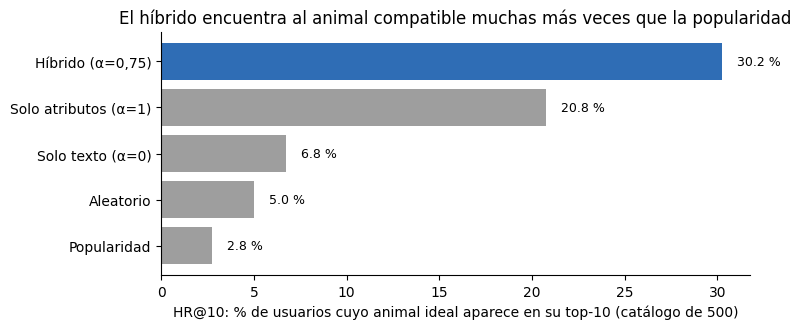

In [16]:
fig, ax = plt.subplots(figsize=(8, 3.4))
orden = resultados["HR@10"].sort_values()
colores_barra = ["#2f6db5" if m.startswith("Híbrido (") else "#9e9e9e" for m in orden.index]
ax.barh(orden.index, 100 * orden.values, color=colores_barra)
for y, v in enumerate(orden.values):
    ax.text(100 * v + 0.8, y, f"{100 * v:.1f} %", va="center", fontsize=9)
ax.set_xlabel("HR@10: % de usuarios cuyo animal ideal aparece en su top-10 (catálogo de 500)")
ax.set_title("El híbrido encuentra al animal compatible muchas más veces que la popularidad")
ax.spines[["top", "right"]].set_visible(False)
plt.tight_layout()
plt.savefig(FIG / "evaluacion_hr10.png", dpi=160)
plt.show()

**Sensibilidad al peso α.** Probamos varios valores de α para justificar el elegido. La cobertura del catálogo se reporta en la sección 11.

In [17]:
sensibilidad = {}
for a in [0.0, 0.25, 0.5, 0.75, 0.9, 1.0]:
    r, _ = evaluar(n_usuarios=200, semilla=7, alpha_hibrido=a, solo=["Híbrido (α=0,75)"])
    sensibilidad[a] = r.iloc[0]["HR@10"]
print("HR@10 según el peso α de los atributos (200 usuarios):")
print(pd.Series(sensibilidad, name="HR@10").rename_axis("α").round(3).to_frame().T)

HR@10 según el peso α de los atributos (200 usuarios):
α      0.00  0.25   0.50  0.75  0.90  1.00
HR@10  0.07  0.18  0.305  0.35  0.37  0.22


## 11. Medición de sesgos y efecto de la mitigación (Parte 3)

Simulamos **300 adoptantes variados** sobre el catálogo completo y medimos la **exposición** que recibe cada grupo en el top-10. La exposición se descuenta por posición (estar en el puesto 1 vale más que en el 10):

$$\mathrm{exposición}(i) = \frac{1}{\log_2(\mathrm{posición}+1)}$$

La **razón de exposición** de un grupo es su porcentaje de la exposición total dividido entre su porcentaje dentro de los candidatos elegibles. **1,0 = trato proporcional**, menos de 1 = subexpuesto.

El procedimiento es **medir antes de mitigar**: (1) medir la versión base, (2) probar una mitigación por hipótesis, (3) calibrar el re-ranking con los grupos que realmente quedaron subexpuestos.

In [18]:
def medir_exposicion(n_usuarios=300, semilla=SEMILLA, **opciones):
    rng = np.random.default_rng(semilla)
    expo = pd.Series(0.0, index=df.index)
    elegibles = pd.Series(0.0, index=df.index)
    puntajes, aparecidos, espacios = [], set(), 0
    for _ in range(n_usuarios):
        q = cuestionario_aleatorio(rng)
        res = sr.recomendar(q=q, k=10, **opciones)
        if res.empty:
            continue
        expo[res["idx"].to_numpy()] += 1 / np.log2(res["posicion"].to_numpy() + 1)
        elegibles += filtros_duros(q, df)
        puntajes.append(res["score"].mean())
        aparecidos |= set(res["idx"])
        espacios += len(res)
    fila = {}
    for col, nombre in GRUPOS.items():
        g = df[col].to_numpy()
        fila[nombre] = (expo[g].sum() / expo.sum()) / (elegibles[g].sum() / elegibles.sum())
    fila["Score medio top-10"] = np.mean(puntajes)
    fila["Animales distintos recomendados"] = len(aparecidos)
    fila["% de espacios con animal distinto"] = len(aparecidos) / espacios
    return pd.Series(fila)


base = medir_exposicion()
imputacion = medir_exposicion(mitigar_presentacion=True)
pd.DataFrame({"Base": base, "Hipótesis: imputar texto de fichas cortas": imputacion}).round(3)

,Base,Hipótesis: imputar texto de fichas cortas
Adulto o senior (≥ 3 años),2.911,3.141
Raza Ley 746 (perros),1.056,1.471
Pelaje negro,0.753,0.762
Sin fotos,1.310,0.653
Descripción < 20 palabras,1.068,0.111
Score medio top-10,0.713,0.707
Animales distintos recomendados,894.000,856.000
% de espacios con animal distinto,0.298,0.285


**Lectura de la versión base:**

- **El motor no reproduce el sesgo de popularidad.** Los animales adultos, que en la realidad tienen 1,41× más riesgo de no ser adoptados, reciben *más* exposición de la proporcional. La razón es una regla del cuestionario: a quien pasa muchas horas fuera se le sugieren animales que no sean cachorros. Las fichas sin fotos tampoco salen castigadas, porque el motor no usa fotos.
- **La hipótesis sobre las descripciones cortas era falsa.** Pensábamos que el TF-IDF castigaría las fichas cortas, pero la normalización L2 del coseno compensa la longitud y quedan cerca de 1,0. La mitigación por imputación las **hundió**, así que se **descarta**.
- **Sesgo indirecto inesperado: pelaje negro.** El color no es una variable del modelo, y aun así los animales negros reciben menos exposición de la proporcional. El color está correlacionado con otros atributos (especie, edad, raza mestiza) que el ranking sí usa. Es un sesgo por **variable proxy**: solo se detecta midiendo.

Con esto calibramos el re-ranking: se impulsa **solo a los grupos con razón menor a 0,9 en la versión base**.

In [19]:
subexpuestos = [col for col, nombre in GRUPOS.items() if base[nombre] < 0.9]
print("Grupos subexpuestos en la versión base:", [GRUPOS[c] for c in subexpuestos])
sr.grupos_impulso = subexpuestos

calibracion = {}
for impulso in [0.005, 0.01, 0.02, 0.03]:
    m = medir_exposicion(rerank=True, impulso=impulso)
    calibracion[impulso] = {GRUPOS[c]: m[GRUPOS[c]] for c in subexpuestos} | {
        "pérdida de score": 1 - m["Score medio top-10"] / base["Score medio top-10"]}
pd.DataFrame(calibracion).T.rename_axis("impulso").round(3)

Grupos subexpuestos en la versión base: ['Pelaje negro']


,Pelaje negro,pérdida de score
impulso,,
0.005,0.952,0.001
0.010,1.132,0.002
0.020,1.410,0.004
0.030,1.645,0.008


In [20]:
# Se elige el impulso que deja al grupo subexpuesto más cerca del trato proporcional (1,0)
IMPULSO = min(calibracion, key=lambda i: abs(min(calibracion[i][GRUPOS[c]] for c in subexpuestos) - 1))
mitigada = medir_exposicion(rerank=True, impulso=IMPULSO)
exposicion = pd.DataFrame({"Base": base, f"Re-ranking calibrado (impulso {IMPULSO})": mitigada})
perdida = 1 - mitigada["Score medio top-10"] / base["Score medio top-10"]
hr_mit, _ = evaluar(solo=["Híbrido (α=0,75)", "Híbrido + re-ranking"], impulso=IMPULSO)
print(f"Impulso elegido: {IMPULSO} · pérdida de relevancia: {perdida:.1%} del score medio")
print("HR@10 sin y con re-ranking:", hr_mit["HR@10"].round(3).to_dict())
exposicion.round(3)

Impulso elegido: 0.005 · pérdida de relevancia: 0.1% del score medio
HR@10 sin y con re-ranking: {'Híbrido (α=0,75)': 0.302, 'Híbrido + re-ranking': 0.29}


,Base,Re-ranking calibrado (impulso 0.005)
Adulto o senior (≥ 3 años),2.911,2.964
Raza Ley 746 (perros),1.056,1.231
Pelaje negro,0.753,0.952
Sin fotos,1.310,1.509
Descripción < 20 palabras,1.068,1.081
Score medio top-10,0.713,0.712
Animales distintos recomendados,894.000,846.000
% de espacios con animal distinto,0.298,0.282


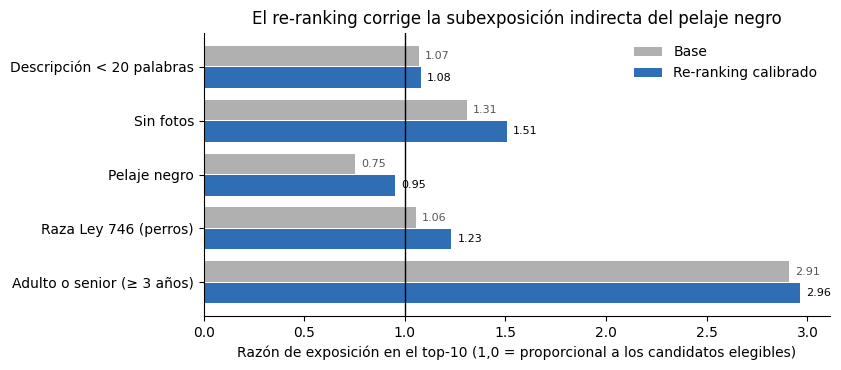

In [21]:
grupos = list(GRUPOS.values())
fig, ax = plt.subplots(figsize=(8.5, 3.8))
y = np.arange(len(grupos))
ax.barh(y + 0.2, exposicion.loc[grupos].iloc[:, 0], height=0.38, color="#b0b0b0", label="Base")
ax.barh(y - 0.2, exposicion.loc[grupos].iloc[:, 1], height=0.38, color="#2f6db5", label="Re-ranking calibrado")
for yy, (v0, v1) in enumerate(zip(exposicion.loc[grupos].iloc[:, 0], exposicion.loc[grupos].iloc[:, 1])):
    ax.text(v0 + 0.03, yy + 0.2, f"{v0:.2f}", va="center", fontsize=8, color="#555555")
    ax.text(v1 + 0.03, yy - 0.2, f"{v1:.2f}", va="center", fontsize=8)
ax.axvline(1, color="black", lw=1)
ax.set_yticks(y, grupos)
ax.set_xlabel("Razón de exposición en el top-10 (1,0 = proporcional a los candidatos elegibles)")
ax.set_title("El re-ranking corrige la subexposición indirecta del pelaje negro")
ax.legend(loc="upper right", frameon=False)
ax.spines[["top", "right"]].set_visible(False)
plt.tight_layout()
plt.savefig(FIG / "exposicion_sesgos.png", dpi=160)
plt.show()

## 12. Conclusiones

- **El filtrado basado en contenido es viable y necesario** en este dominio: cada animal es un ítem único sin historial, y aun así el sistema lo puede recomendar desde que se publica (sección 9).
- **El criterio de similaridad** (Gower ponderada por el usuario + coseno TF-IDF) supera claramente a la popularidad y al azar para encontrar al animal compatible (sección 10), con **cero violaciones** de las restricciones duras.
- **El cuestionario resuelve el arranque en frío del usuario** y Rocchio permite afinar el perfil en la misma sesión (sección 8).
- **Los datos traen sesgos del mundo real** (sección 2), pero el motor no los reproduce porque no usa la popularidad. Medir reveló un sesgo indirecto (pelaje negro) que se corrige con un re-ranking calibrado y una pérdida pequeña de relevancia. También mostró que una mitigación "intuitiva" (imputar el texto de fichas cortas) empeoraba las cosas (sección 11).
- **Limitación principal:** pocas fichas describen la convivencia con niños u otros animales. La mejora más rentable no es algorítmica: es una **ficha estándar** para las fundaciones.